Business problem: Identify which passengers were more likely to survive the Titanic disaster based on their characteristics.

Machine Learning objective: Predict whether a passenger survived.

survived = 1 → Passenger survived.
survived = 0 → Passenger did not survive.

Type of Machine Learning: Supervised Learning → Binary Classification.

In [1]:
import pandas as pd
df = pd.read_csv("https://hbiostat.org/data/repo/titanic3.csv")

In [2]:
df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.00,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.00,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 210.3 KB


                                             Understand Every Column

| Column      | Meaning                           | Data type | Use                         |
| ----------- | --------------------------------- | --------- | --------------------------- |
| `pclass`    | Passenger class (1st, 2nd, 3rd)   | Integer   | Feature                     |
| `survived`  | Survival status (0 or 1)          | Integer   | Target                      |
| `name`      | Passenger's name                  | String    | Feature engineering         |
| `sex`       | Passenger's sex                   | String    | Feature                     |
| `age`       | Passenger's age                   | Float     | Feature                     |
| `sibsp`     | Number of siblings/spouses aboard | Integer   | Feature                     |
| `parch`     | Number of parents/children aboard | Integer   | Feature                     |
| `ticket`    | Ticket number                     | String    | Possible feature            |
| `fare`      | Ticket fare                       | Float     | Feature                     |
| `cabin`     | Cabin number                      | String    | Possible feature            |
| `embarked`  | Port of embarkation               | String    | Feature                     |
| `boat`      | Lifeboat identifier               | String    | **Exclude from prediction** |
| `body`      | Body identification number        | Float     | **Exclude from prediction** |
| `home.dest` | Home destination                  | String    | Possible feature            |


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nLast 5 Rows:")
display(df.tail())

Dataset Shape: (1309, 14)

First 5 Rows:


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.00,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.92,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.00,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.00,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"



Last 5 Rows:


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
1304,3,0,"Zabour, Miss. Hileni",female,14.5,1,0,2665,14.4542,NaN,C,NaN,328.0,NaN
1305,3,0,"Zabour, Miss. Thamine",female,NaN,1,0,2665,14.4542,NaN,C,NaN,NaN,NaN
1306,3,0,"Zakarian, Mr. Mapriededer",male,26.5,0,0,2656,7.2250,NaN,C,NaN,304.0,NaN
1307,3,0,"Zakarian, Mr. Ortin",male,27.0,0,0,2670,7.2250,NaN,C,NaN,NaN,NaN
1308,3,0,"Zimmerman, Mr. Leo",male,29.0,0,0,315082,7.8750,NaN,S,NaN,NaN,NaN


In [6]:
##Statistical analysis
print("Numerical Column Statistics:")
display(df.describe().round(2))

print("\nCategorical Column Statistics:")
display(df.describe(include="object"))

Numerical Column Statistics:


,pclass,survived,age,sibsp,parch,fare,body
count,1309.00,1309.00,1046.00,1309.00,1309.00,1308.00,121.00
mean,2.29,0.38,29.88,0.50,0.39,33.30,160.81
std,0.84,0.49,14.41,1.04,0.87,51.76,97.70
min,1.00,0.00,0.17,0.00,0.00,0.00,1.00
25%,2.00,0.00,21.00,0.00,0.00,7.90,72.00
50%,3.00,0.00,28.00,0.00,0.00,14.45,155.00
75%,3.00,1.00,39.00,1.00,0.00,31.28,256.00
max,3.00,1.00,80.00,8.00,9.00,512.33,328.00



Categorical Column Statistics:


C:\Users\SASWAT\AppData\Local\Temp\ipykernel_28760\2276438865.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,name,sex,ticket,cabin,embarked,boat,home.dest
count,1309,1309,1309,295,1307,486,745
unique,1307,2,929,186,3,27,369
top,"Connolly, Miss. Kate",male,CA. 2343,C23 C25 C27,S,13,"New York, NY"
freq,2,843,11,6,914,39,64


In [7]:
##Check the target variable
print("Survival Counts:")
print(df["survived"].value_counts())

print("\nSurvival Percentages:")
print(
    (df["survived"].value_counts(normalize=True) * 100).round(2)
)

Survival Counts:
survived
0    809
1    500
Name: count, dtype: int64

Survival Percentages:
survived
0    61.8
1    38.2
Name: proportion, dtype: float64


In [8]:
##Check missing values
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing = missing[missing["Missing_Count"] > 0]
missing = missing.sort_values(
    by="Missing_Percentage",
    ascending=False
)

display(missing)

,Missing_Count,Missing_Percentage
body,1188,90.76
cabin,1014,77.46
boat,823,62.87
home.dest,564,43.09
age,263,20.09
embarked,2,0.15
fare,1,0.08


In [9]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


Total passengers: 1,309
Did not survive: 809 (61.8%)
Survived: 500 (38.2%)
Exact duplicate rows: 0
Columns with missing values: 7

Data Cleaning and Quality Analysis

1. Business understanding of missing values

First, we need to decide how to handle each column.

| Column      | Missing % | Our initial decision                    | Reason                                                            |
| ----------- | --------: | --------------------------------------- | ----------------------------------------------------------------- |
| `body`      |    90.76% | Exclude from the initial model          | Mostly missing and potentially leaks post-disaster information    |
| `cabin`     |    77.46% | Investigate; extract deck if useful     | Missingness is substantial, but cabin information may be valuable |
| `boat`      |    62.87% | Exclude from the initial model          | Lifeboat information can reveal the survival outcome              |
| `home.dest` |    43.09% | Investigate; possibly exclude initially | Many missing values and potentially high-cardinality categories   |
| `age`       |    20.09% | Impute missing values                   | Age may help predict survival                                     |
| `embarked`  |     0.15% | Impute missing values                   | Only two values are missing                                       |
| `fare`      |     0.08% | Impute the missing value                | Only one value is missing                                         |


Missing-value analysis

In [15]:
columns_to_check = [
    "age",
    "cabin",
    "embarked",
    "home.dest"
]

for col in columns_to_check:

    print(f"\nColumn: {col}")

    missing_status = df[col].isnull().map({
        True: "Missing",
        False: "Available"
    })

    result = df.groupby(missing_status)["survived"].agg(
        Passenger_Count="count",
        Survival_Rate="mean"
    )

    result["Survival_Rate"] = (
        result["Survival_Rate"] * 100
    ).round(2)

    display(result)


Column: age


,Passenger_Count,Survival_Rate
age,,
Available,1046,40.82
Missing,263,27.76



Column: cabin


,Passenger_Count,Survival_Rate
cabin,,
Available,295,65.42
Missing,1014,30.28



Column: embarked


,Passenger_Count,Survival_Rate
embarked,,
Available,1307,38.1
Missing,2,100.0



Column: home.dest


,Passenger_Count,Survival_Rate
home.dest,,
Available,745,46.58
Missing,564,27.13


Age: Passengers with known ages had a 40.82% survival rate, compared with 27.76% for passengers with missing ages.
Cabin: Passengers with known cabin information had a 65.42% survival rate, compared with 30.28% for those with missing cabin information.
Home destination: Passengers with known destinations had a 46.58% survival rate, compared with 27.13% for those with missing destinations.
Embarked: Only two values are missing, so we cannot draw meaningful conclusions from that tiny group.

In [17]:
# Check cleaned dataset
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
display(
    df.isnull()
    .sum()
    .to_frame("Missing_Count")
    .query("Missing_Count > 0")
)

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (1309, 14)

Missing Values:


,Missing_Count
age,263
fare,1
cabin,1014
embarked,2
boat,823
body,1188
home.dest,564



Duplicate Rows: 0

Data Types:
pclass         int64
survived       int64
name             str
sex              str
age          float64
sibsp          int64
parch          int64
ticket           str
fare         float64
cabin            str
embarked         str
boat             str
body         float64
home.dest        str
dtype: object


       Create a fresh working copy

In [18]:
df_clean = df.copy()

print("Original shape:", df.shape)
print("Working copy shape:", df_clean.shape)

Original shape: (1309, 14)
Working copy shape: (1309, 14)


In [19]:
##Remove columns that cause data leakage
df_clean = df_clean.drop(columns=["boat", "body"])

print("Shape after dropping columns:", df_clean.shape)

Shape after dropping columns: (1309, 12)


Why remove these columns?

boat: Lifeboat information can reveal whether a passenger survived.
body: Body identification information is associated with events after the disaster.

We should not use these columns to predict survival.

Handle missing values

In [20]:
# Fill missing age with the median
df_clean["age"] = df_clean["age"].fillna(
    df_clean["age"].median()
)

# Fill missing fare with the median
df_clean["fare"] = df_clean["fare"].fillna(
    df_clean["fare"].median()
)

# Fill missing embarked with the mode
df_clean["embarked"] = df_clean["embarked"].fillna(
    df_clean["embarked"].mode()[0]
)

print("Missing values handled for age, fare, and embarked.")

Missing values handled for age, fare, and embarked.


In [21]:
##Verify the cleaning
print("Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
display(
    df_clean.isnull()
    .sum()
    .to_frame("Missing_Count")
    .query("Missing_Count > 0")
)

print("\nDuplicate Rows:", df_clean.duplicated().sum())

Dataset Shape: (1309, 12)

Missing Values:


,Missing_Count
cabin,1014
home.dest,564



Duplicate Rows: 0


Survival by Passenger Class
Business question

Were first-class passengers more likely to survive than second- and third-class passengers?

In [23]:
##Calculate survival rates
class_analysis = df_clean.groupby("pclass").agg(
    Total_Passengers=("survived", "count"),
    Survivors=("survived", "sum"),
    Survival_Rate=("survived", "mean")
)

class_analysis["Survival_Rate"] = (
    class_analysis["Survival_Rate"] * 100
).round(2)

display(class_analysis)

,Total_Passengers,Survivors,Survival_Rate
pclass,,,
1,323,200,61.92
2,277,119,42.96
3,709,181,25.53


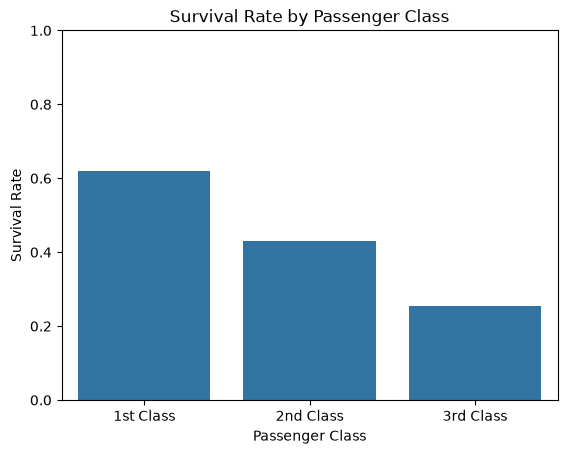

In [25]:
##Visualize survival rates
import matplotlib.pyplot as plt
import seaborn as sns

sns.barplot(
    data=df_clean,
    x="pclass",
    y="survived",
    errorbar=None
)

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")
plt.xticks(
    [0, 1, 2],
    ["1st Class", "2nd Class", "3rd Class"]
)
plt.ylim(0, 1)
plt.show()

Analyze Survival by Gender

In [26]:
gender_analysis = df_clean.groupby("sex").agg(
    Total_Passengers=("survived", "count"),
    Survivors=("survived", "sum"),
    Survival_Rate=("survived", "mean")
)

gender_analysis["Survival_Rate"] = (
    gender_analysis["Survival_Rate"] * 100
).round(2)

display(gender_analysis)

,Total_Passengers,Survivors,Survival_Rate
sex,,,
female,466,339,72.75
male,843,161,19.10


In the Titanic dataset, female passengers had a survival rate of 72.75%, compared with 19.10% for male passengers. This indicates a strong association between gender and survival. However, this analysis alone does not establish causation.

Analyze Survival by Age

In [ ]:
Were children more likely to survive than adults?

Child: Age 1–12.
Teenager: Age 12–18.
Adult: Age 18–60.
Senior: Age above 60.

In [28]:
# Create age groups
df_clean["age_group"] = pd.cut(
    df_clean["age"],
    bins=[0, 12, 18, 60, float("inf")],
    labels=["Child", "Teenager", "Adult", "Senior"],
    right=True
)

# Calculate survival statistics
age_analysis = df_clean.groupby(
    "age_group", observed=True
).agg(
    Total_Passengers=("survived", "count"),
    Survivors=("survived", "sum"),
    Survival_Rate=("survived", "mean")
)

age_analysis["Survival_Rate"] = (
    age_analysis["Survival_Rate"] * 100
).round(2)

display(age_analysis)

,Total_Passengers,Survivors,Survival_Rate
age_group,,,
Child,94,54,57.45
Teenager,99,41,41.41
Adult,1083,397,36.66
Senior,33,8,24.24


The analysis revealed differences in survival rates across age groups. Children had the highest survival rate at 57.45%, followed by teenagers at 41.41% and adults at 36.66%. Seniors had the lowest survival rate at 24.24%. These findings suggest that age group may be an important feature for predicting passenger survival.

Analyze Survival by Embarkation Port

Now let's investigate whether survival rates differed according to the port where passengers boarded the Titanic.

In this dataset:

C = Cherbourg
Q = Queenstown
S = Southampton

In [29]:
embarked_analysis = df_clean.groupby("embarked").agg(
    Total_Passengers=("survived", "count"),
    Survivors=("survived", "sum"),
    Survival_Rate=("survived", "mean")
)

embarked_analysis["Survival_Rate"] = (
    embarked_analysis["Survival_Rate"] * 100
).round(2)

display(embarked_analysis)

,Total_Passengers,Survivors,Survival_Rate
embarked,,,
C,270,150,55.56
Q,123,44,35.77
S,916,306,33.41


The analysis showed differences in survival rates by embarkation port. Passengers who embarked at Cherbourg had the highest survival rate at 55.56%, compared with 35.77% at Queenstown and 33.41% at Southampton. However, embarkation port may be associated with other factors, such as passenger class, so these results do not establish a causal relationship.

Analyze Survival by Passenger Class and Gender

Did survival rates differ between men and women within each passenger class?

In [31]:
class_gender_analysis = df_clean.pivot_table(
    index="pclass",
    columns="sex",
    values="survived",
    aggfunc="mean",
    observed=True
)

class_gender_analysis = (class_gender_analysis * 100).round(2)

display(class_gender_analysis)

sex,female,male
pclass,,
1,96.53,34.08
2,88.68,14.62
3,49.07,15.21


                                    MACHINE LEARNING PART

In [ ]:
What are we predicting?

Our business question is:

Can we predict whether a Titanic passenger survived using information such as age, gender, and passenger class?

Target (y): survived
0 = Did not survive
1 = Survived
Features (X): Information used by the model to make predictions.

In [32]:
# Select features for Machine Learning
features = [
    "pclass",
    "sex",
    "age",
    "sibsp",
    "parch",
    "fare",
    "embarked"
]

# Independent variables
X = df_clean[features]

# Dependent variable
y = df_clean["survived"]

# Check the data
print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (1309, 7)
Target shape: (1309,)

Feature columns:
['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']

Target distribution:
survived
0    809
1    500
Name: count, dtype: int64


Train-Test Split

We want the model to learn patterns from one part of the data and then test how well it predicts outcomes for passengers it hasn't seen before.

Training data (80%): Used to train the model.
Testing data (20%): Used to evaluate the model on unseen records.

In [33]:
from sklearn.model_selection import train_test_split

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the shapes
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (1047, 7)
Testing features: (262, 7)
Training target: (1047,)
Testing target: (262,)


Logistic Regression needs numerical input. Therefore, we must convert categorical features into numerical representations and handle missing values.

Important: We'll fit preprocessing on the training data only to avoid data leakage.

In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Identify numerical and categorical features
numeric_features = [
    "pclass", "age", "sibsp", "parch", "fare"
]

categorical_features = ["sex", "embarked"]

# Preprocess numerical columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


What does Logistic Regression do?

Our goal is to predict whether a Titanic passenger survived.

0 = Did not survive
1 = Survived

Logistic Regression estimates the probability of survival using passenger features such as age, gender, and passenger class.

In [35]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create the complete ML pipeline
lr_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Evaluate my  Model

After training, let's measure how well it predicts survival for passengers in the test dataset.

In [36]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Predict on unseen test data
y_pred = lr_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.2%}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 80.92%

Confusion Matrix:
[[141  21]
 [ 29  71]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       162
           1       0.77      0.71      0.74       100

    accuracy                           0.81       262
   macro avg       0.80      0.79      0.79       262
weighted avg       0.81      0.81      0.81       262



In [ ]:
Actual Outcome	       Predicted Not Survived	        Predicted Survived
Not survived (0)	          141	                          21
Survived (1)	               29	                          71

Here's what this means:

141: Correctly predicted passengers who did not survive.
21: Predicted survival, but those passengers did not survive.
29: Predicted non-survival, but those passengers survived.
71: Correctly predicted passengers who survived.
Important finding

my model identified 71 of the 100 actual survivors.

That gives a survivor recall of:

$$ \text{Recall}=\frac{71}{71+29}\times100=71\% $$

The model missed 29 actual survivors, so there is room for improvement.

    Random Forest

Random Forest combines multiple decision trees and can learn more complex patterns.

In [37]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

# Create the Random Forest pipeline
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train the model
rf_model.fit(X_train, y_train)

# Predict on test data
rf_pred = rf_model.predict(X_test)

# Evaluate the model
print(f"Random Forest Accuracy: {accuracy_score(y_test, rf_pred):.2%}")

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 79.01%

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.80      0.83       162
           1       0.71      0.77      0.74       100

    accuracy                           0.79       262
   macro avg       0.78      0.79      0.78       262
weighted avg       0.79      0.79      0.79       262



Next, compare ROC-AUC

ROC-AUC measures how well a model distinguishes between the two classes: survived (1) and did not survive (0).

In [38]:
from sklearn.metrics import roc_auc_score

# Get survival probabilities from both models
lr_prob = lr_model.predict_proba(X_test)[:, 1]
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
lr_auc = roc_auc_score(y_test, lr_prob)
rf_auc = roc_auc_score(y_test, rf_prob)

print(f"Logistic Regression ROC-AUC: {lr_auc:.4f}")
print(f"Random Forest ROC-AUC:      {rf_auc:.4f}")

Logistic Regression ROC-AUC: 0.8670
Random Forest ROC-AUC:      0.8636


Model Comparison Results
Metric	Logistic Regression	Random Forest	Winner
Accuracy	80.92%	79.01%	Logistic Regression
Precision (Survived)	77%	71%	Logistic Regression
Recall (Survived)	71%	77%	Random Forest
F1-score (Survived)	0.74	0.74	Tie
ROC-AUC	0.8670	0.8636	Logistic Regression
What does ROC-AUC tell us?
Logistic Regression: 0.8670
Random Forest: 0.8636

Both models distinguish survivors from non-survivors reasonably well. Logistic Regression has a slightly higher ROC-AUC, but the difference is very small.

Current winner: Logistic Regression, based on accuracy and ROC-AUC. However, Random Forest has higher recall for survivors.

Visualize Model Performance

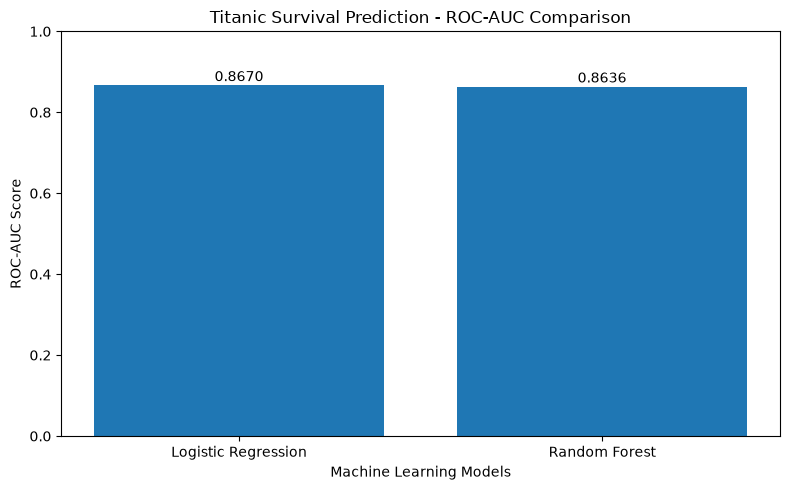

In [39]:
import matplotlib.pyplot as plt

model_names = ["Logistic Regression", "Random Forest"]
roc_auc_scores = [lr_auc, rf_auc]

plt.figure(figsize=(8, 5))
plt.bar(model_names, roc_auc_scores)

plt.title("Titanic Survival Prediction - ROC-AUC Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("ROC-AUC Score")
plt.ylim(0, 1)

for i, score in enumerate(roc_auc_scores):
    plt.text(i, score + 0.01, f"{score:.4f}", ha="center")

plt.tight_layout()
plt.show()

We'll use Logistic Regression first because it currently has the highest accuracy and ROC-AUC.

Feature Importance 

In [40]:
import pandas as pd
import matplotlib.pyplot as plt

# Get the fitted preprocessing pipeline
preprocessor_fitted = lr_model.named_steps["preprocessor"]

# Get the trained Logistic Regression model
classifier = lr_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = preprocessor_fitted.get_feature_names_out()

# Get model coefficients
coefficients = classifier.coef_[0]

# Create feature importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients,
    "Absolute_Importance": abs(coefficients)
})

# Sort by absolute importance
feature_importance = feature_importance.sort_values(
    by="Absolute_Importance",
    ascending=False
)

display(feature_importance)

,Feature,Coefficient,Absolute_Importance
6,cat__sex_male,-1.296770,1.296770
5,cat__sex_female,1.184499,1.184499
0,num__pclass,-0.745179,0.745179
7,cat__embarked_C,0.469004,0.469004
1,num__age,-0.464082,0.464082
8,cat__embarked_Q,-0.366326,0.366326
2,num__sibsp,-0.312973,0.312973
9,cat__embarked_S,-0.214949,0.214949
4,num__fare,0.064062,0.064062
3,num__parch,0.007520,0.007520


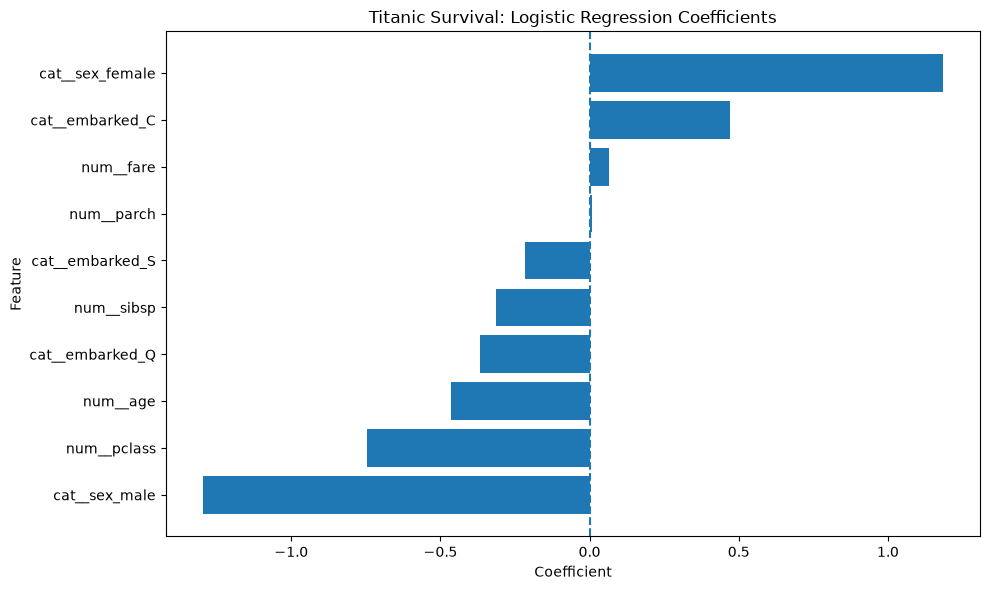

In [42]:

import matplotlib.pyplot as plt

# Sort coefficients from lowest to highest
plot_data = feature_importance.sort_values("Coefficient")

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data["Feature"],
    plot_data["Coefficient"]
)

plt.axvline(x=0, linestyle="--")

plt.title("Titanic Survival: Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()



Female: Positive coefficient (+1.184) — associated with higher predicted survival odds.
Male: Negative coefficient (-1.297) — associated with lower predicted survival odds.
Passenger class: Negative coefficient (-0.745) — passengers in higher-numbered classes had lower predicted survival odds.
Age: Negative coefficient (-0.464) — older passengers had lower predicted survival odds.
Fare: Small positive coefficient (+0.064).
Parents/children aboard (parch): Coefficient close to zero (+0.008).

Cross-validation

In [43]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Create 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate Logistic Regression on the training data only
cv_scores = cross_val_score(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Cross-validation scores:", cv_scores)
print(f"Mean CV Accuracy: {cv_scores.mean():.2%}")
print(f"Standard Deviation: {cv_scores.std():.2%}")

Cross-validation scores: [0.78095238 0.76666667 0.77990431 0.81339713 0.79425837]
Mean CV Accuracy: 78.70%
Standard Deviation: 1.58%


Next, improve Logistic Regression using hyperparameter tuning

In [45]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create a fresh pipeline
lr_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

# Define hyperparameters to test
param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__solver": ["lbfgs"],
    "classifier__class_weight": [None, "balanced"]
}

# Create 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Run grid search
grid_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)

# Train and tune using training data only
grid_search.fit(X_train, y_train)

# Display results
print("Best Parameters:", grid_search.best_params_)
print(f"Best CV Accuracy: {grid_search.best_score_:.2%}")



Best Parameters: {'classifier__C': 1, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}
Best CV Accuracy: 78.70%


Evaluate the tuned model on the test set

Now we need to check whether the tuned model performs better on data it hasn't trained on.

In [47]:

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score,
    confusion_matrix
)

# Get the best model selected by GridSearchCV
best_lr_model = grid_search.best_estimator_

# Predict on the untouched test set
tuned_pred = best_lr_model.predict(X_test)
tuned_prob = best_lr_model.predict_proba(X_test)[:, 1]

# Evaluate performance
print(f"Tuned Model Accuracy: {accuracy_score(y_test, tuned_pred):.2%}")
print(f"Tuned Model ROC-AUC: {roc_auc_score(y_test, tuned_prob):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, tuned_pred))

print("\nClassification Report:")
print(classification_report(y_test, tuned_pred))


Tuned Model Accuracy: 80.92%
Tuned Model ROC-AUC: 0.8670

Confusion Matrix:
[[141  21]
 [ 29  71]]

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       162
           1       0.77      0.71      0.74       100

    accuracy                           0.81       262
   macro avg       0.80      0.79      0.79       262
weighted avg       0.81      0.81      0.81       262



Titanic Survival Prediction — Model Insights

1. Overall Model Performance
Metric	Result	Interpretation
Accuracy	80.92%	Correctly classified 212 of 262 passengers
ROC-AUC	0.8670	Good ability to distinguish survivors from non-survivors
Precision (Survived)	77%	Of passengers predicted to survive, about 77% actually survived
Recall (Survived)	71%	Identified 71% of the passengers who actually survived
F1-score (Survived)	0.74	Balances survivor precision and recall
Cross-validation accuracy	78.70%	Average accuracy across five validation folds

Key finding: Your model achieves approximately 81% test accuracy and a ROC-AUC of 0.867. These results indicate useful predictive performance on this test set, although performance may vary on other data.

2. Confusion Matrix Insights

Your confusion matrix:

                 Predicted
                 Died   Survived
Actual Died       141      21
Actual Survived    29      71
Outcome	Passengers	Meaning
True negatives	141	Correctly predicted not to survive
False positives	21	Predicted to survive, but did not
False negatives	29	Predicted not to survive, but survived
True positives	71	Correctly predicted to survive
Business interpretation
141 passengers: Correctly identified as non-survivors.
71 passengers: Correctly identified as survivors.
21 passengers: Incorrectly predicted to survive.
29 passengers: Survivors the model failed to identify.

The model correctly classified 212 passengers out of 262.

3. Which passengers were more likely to survive?

Based on your earlier exploratory data analysis:

Passenger group	Survival rate
Female	72.75%
Male	19.10%
First class	61.92%
Second class	42.96%
Third class	25.53%
Children	57.45%
Adults	36.66%
Seniors	24.24%
Key findings

Gender: Female passengers had a substantially higher survival rate than male passengers in your dataset.

Passenger class: First-class passengers had a higher survival rate than second- and third-class passengers.

Age: Children had a higher survival rate than adults and seniors in your analysis.

These are descriptive relationships in the dataset, not proof that these characteristics alone determined survival.

4. Model interpretation insights

Your Logistic Regression coefficients showed:

Feature	Coefficient	Interpretation
sex_male	-1.297	Associated with lower predicted survival odds
sex_female	+1.184	Associated with higher predicted survival odds
pclass	-0.745	Higher class numbers are associated with lower survival odds
age	-0.464	Greater age is associated with lower survival odds
embarked_C	+0.469	Positive association relative to the encoding reference
fare	+0.064	Small positive coefficient
parch	+0.008	Coefficient close to zero

Important: These coefficients describe model associations, not causal effects. Because numeric features were standardized, coefficient magnitudes are interpreted on their transformed scales.

5. Cross-validation and generalization

Your five-fold cross-validation results were:

Mean accuracy: 78.70%
Standard deviation: 1.58%
Test accuracy: 80.92%

The cross-validation scores varied relatively little, which suggests reasonably consistent performance across those folds.

The test accuracy is about 2.22 percentage points higher than the cross-validation mean. This difference does not by itself indicate overfitting.

6. Did hyperparameter tuning improve the model?
Metric	Original model	Tuned model
Test accuracy	80.92%	80.92%
ROC-AUC	0.8670	0.8670
Survivor precision	77%	77%
Survivor recall	71%	71%

Conclusion: Grid search did not improve performance. It selected the same parameter settings as the original model.

There is no evidence from these results that the tuned model is better than the original.

7. Final business conclusion

Your Titanic project demonstrates how historical passenger data can be used to predict survival outcomes.

The model achieved 80.92% accuracy and a ROC-AUC of 0.8670 on the held-out test set. Gender, passenger class, and age showed important associations with survival in your EDA and Logistic Regression analysis.

However, the model missed 29 actual survivors, so survivor recall could be improved if identifying survivors is the main objective.

Remember that the Titanic dataset is historical and relatively small. These results should not be interpreted as evidence that the model could reliably predict survival in a real emergency.

In [ ]:
Save best model

In [48]:

import joblib
import os

# Create a folder for saved models
os.makedirs("models", exist_ok=True)

# Save the selected model
joblib.dump(best_lr_model, "models/titanic_survival_model.pkl")

print("Model saved successfully!")
print("File path: models/titanic_survival_model.pkl")


Model saved successfully!
File path: models/titanic_survival_model.pkl


In [49]:

import joblib
import os

# Check whether the model file exists
model_path = "models/titanic_survival_model.pkl"

if os.path.exists(model_path):
    loaded_model = joblib.load(model_path)
    print("Model loaded successfully!")
else:
    print("Model file not found. Check your file path.")


Model loaded successfully!


In [ ]:
Test Make a prediction

In [50]:
import pandas as pd

# Create data for one new passenger
new_passenger = pd.DataFrame([{
    "pclass": 1,
    "sex": "female",
    "age": 25,
    "sibsp": 0,
    "parch": 0,
    "fare": 80.0,
    "embarked": "C"
}])

# Predict survival
prediction = loaded_model.predict(new_passenger)

# Predict survival probability
probability = loaded_model.predict_proba(new_passenger)[0][1]

# Display results
if prediction[0] == 1:
    print("Prediction: Passenger is likely to SURVIVE.")
else:
    print("Prediction: Passenger is likely NOT to survive.")

print(f"Predicted survival probability: {probability:.2%}")

Prediction: Passenger is likely to SURVIVE.
Predicted survival probability: 95.56%


Saved ML model is working

                               Build a FastAPI service

Now I'll turn my ML model into an API so other applications can send passenger details and receive survival predictions.

What is FastAPI?

FastAPI lets you expose your Python model through an HTTP API. Later, you can test it in a browser or connect it to another application.

In [51]:
%pip install fastapi uvicorn


   ---------------------------------------- 0/2 [opentelemetry-api]
   ---------------------------------------- 0/2 [opentelemetry-api]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   -------------------- ------------------- 1/2 [fastapi]
   ---------------------------------------- 2/2 [fastapi]

Note: you may need to restart the kernel to use updated packages.


Why do we need these libraries?

fastapi — creates the API.
uvicorn — runs the API server.

I'll create main.py for your Titanic Survival Prediction API.

 — Create the FastAPI application
1. Create main.py

In [52]:
%%writefile main.py

from fastapi import FastAPI
from pydantic import BaseModel, Field
import pandas as pd
import joblib

# Load the trained ML model
model = joblib.load("models/titanic_survival_model.pkl")

# Create the FastAPI application
app = FastAPI(
    title="Titanic Survival Prediction API",
    description="Predict passenger survival using a trained Machine Learning model",
    version="1.0.0"
)

# Define and validate input data
class PassengerInput(BaseModel):
    pclass: int = Field(ge=1, le=3)
    sex: str
    age: float = Field(ge=0, le=100)
    sibsp: int = Field(ge=0)
    parch: int = Field(ge=0)
    fare: float = Field(ge=0)
    embarked: str

# Create a prediction endpoint
@app.post("/predict")
def predict_survival(passenger: PassengerInput):

    passenger_data = pd.DataFrame([passenger.model_dump()])

    prediction = int(model.predict(passenger_data)[0])
    probability = float(model.predict_proba(passenger_data)[0][1])

    return {
        "prediction": prediction,
        "survival_status": (
            "Likely to survive" if prediction == 1
            else "Likely not to survive"
        ),
        "survival_probability": round(probability, 4)
    }

# Health-check endpoint
@app.get("/")
def home():
    return {
        "message": "Titanic Survival Prediction API is running!"
    }

Writing main.py


In [54]:
import os
import sys
import subprocess

# Check current project directory
print("Current directory:", os.getcwd())

# Check whether main.py exists
print("main.py exists:", os.path.exists("main.py"))

# Check whether the saved model exists
print(
    "Model exists:",
    os.path.exists("models/titanic_survival_model.pkl")
)

# Start FastAPI server
if os.path.exists("main.py"):
    process = subprocess.Popen(
        [
            sys.executable,
            "-m",
            "uvicorn",
            "main:app",
            "--host",
            "127.0.0.1",
            "--port",
            "8000"
        ],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True
    )

    print("Server process started.")
else:
    print("ERROR: main.py not found. Check your project directory.")

Current directory: C:\Users\SASWAT
main.py exists: True
Model exists: True
Server process started.


In [55]:
import time

time.sleep(3)

if process.poll() is None:
    print("Server process is running.")
else:
    print("Server failed to start.")

print("Server logs:")
print(process.stdout.read() if process.poll() is not None else "No startup error detected yet.")

Server process is running.
Server logs:
No startup error detected yet.


In [56]:
import requests

try:
    response = requests.get("http://127.0.0.1:8000", timeout=5)
    print("Status:", response.status_code)
    print("Response:", response.text)
except requests.RequestException as e:
    print("Server connection error:", e)

Status: 200
Response: {"message":"Titanic Survival Prediction API is running!"}


In [1]:
%%writefile requirements.txt

fastapi
uvicorn
pandas
scikit-learn
joblib

Writing requirements.txt


Create a ZIP file

In [3]:
import os
import zipfile

project_folder = os.getcwd()
zip_name = "Titanic_Survival_API.zip"

files_to_include = [
    "main.py",
    "requirements.txt",
    "models/titanic_survival_model.pkl"
]

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file in files_to_include:
        if os.path.exists(file):
            zipf.write(file, arcname=file)
            print("Added:", file)
        else:
            print("Missing:", file)

print("\nZIP created:", os.path.abspath(zip_name))

Added: main.py
Added: requirements.txt
Added: models/titanic_survival_model.pkl

ZIP created: C:\Users\SASWAT\Titanic_Survival_API.zip
